Inventory Control Tower

Enterprise Inventory Monitoring System

Objectives

1. Monitor inventory health
2. Detect stockout risks
3. Detect excess inventory
4. Track forecast accuracy
5. Prioritize executive actions

In [1]:
## Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [2]:
## Create Control Tower Dataset

control_tower_df = pd.DataFrame({

    "Item":[
        "TV",
        "Laptop",
        "Headphones",
        "Keyboard",
        "Monitor"
    ],

    "Inventory":[
        500,
        150,
        1000,
        350,
        200
    ],

    "Forecast":[
        400,
        250,
        800,
        300,
        225
    ],

    "Actual_Demand":[
        450,
        300,
        750,
        290,
        275
    ],

    "Supplier_Fill_Rate":[
        98,
        85,
        96,
        99,
        88
    ]

})

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate
0,TV,500,400,450,98
1,Laptop,150,250,300,85
2,Headphones,1000,800,750,96
3,Keyboard,350,300,290,99
4,Monitor,200,225,275,88


In [3]:
## Calculate Forecast Error

control_tower_df["Forecast_Error"] = (

    control_tower_df["Forecast"]

    - control_tower_df["Actual_Demand"]

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error
0,TV,500,400,450,98,-50
1,Laptop,150,250,300,85,-50
2,Headphones,1000,800,750,96,50
3,Keyboard,350,300,290,99,10
4,Monitor,200,225,275,88,-50


In [4]:
## Forecast Accuracy

control_tower_df["Forecast_Accuracy"] = (

    100 -

    (abs(
        control_tower_df["Forecast_Error"]
    )

    /

    control_tower_df["Actual_Demand"])

    * 100

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy
0,TV,500,400,450,98,-50,88.888889
1,Laptop,150,250,300,85,-50,83.333333
2,Headphones,1000,800,750,96,50,93.333333
3,Keyboard,350,300,290,99,10,96.551724
4,Monitor,200,225,275,88,-50,81.818182


In [5]:
## Weeks of Supply

control_tower_df["Weeks_of_Supply"] = (

    control_tower_df["Inventory"]

    /

    (control_tower_df["Actual_Demand"] / 4)

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply
0,TV,500,400,450,98,-50,88.888889,4.444444
1,Laptop,150,250,300,85,-50,83.333333,2.000000
2,Headphones,1000,800,750,96,50,93.333333,5.333333
3,Keyboard,350,300,290,99,10,96.551724,4.827586
4,Monitor,200,225,275,88,-50,81.818182,2.909091


In [6]:
## Inventory Status

control_tower_df["Inventory_Status"] = np.where(

    control_tower_df["Weeks_of_Supply"] > 8,

    "Overstock",

    np.where(

        control_tower_df["Weeks_of_Supply"] < 2,

        "Stockout Risk",

        "Balanced"

    )

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply,Inventory_Status
0,TV,500,400,450,98,-50,88.888889,4.444444,Balanced
1,Laptop,150,250,300,85,-50,83.333333,2.000000,Balanced
2,Headphones,1000,800,750,96,50,93.333333,5.333333,Balanced
3,Keyboard,350,300,290,99,10,96.551724,4.827586,Balanced
4,Monitor,200,225,275,88,-50,81.818182,2.909091,Balanced


In [7]:
## Supplier Risk

control_tower_df["Supplier_Risk"] = np.where(

    control_tower_df["Supplier_Fill_Rate"] < 90,

    "High Risk",

    "Normal"

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply,Inventory_Status,Supplier_Risk
0,TV,500,400,450,98,-50,88.888889,4.444444,Balanced,Normal
1,Laptop,150,250,300,85,-50,83.333333,2.000000,Balanced,High Risk
2,Headphones,1000,800,750,96,50,93.333333,5.333333,Balanced,Normal
3,Keyboard,350,300,290,99,10,96.551724,4.827586,Balanced,Normal
4,Monitor,200,225,275,88,-50,81.818182,2.909091,Balanced,High Risk


In [8]:
## Control Tower Risk Score

control_tower_df["Risk_Score"] = (

    (control_tower_df["Inventory_Status"] == "Stockout Risk").astype(int)

    +

    (control_tower_df["Supplier_Risk"] == "High Risk").astype(int)

)

In [9]:
## Executive Priority

control_tower_df["Priority"] = np.where(

    control_tower_df["Risk_Score"] >= 2,

    "Critical",

    np.where(

        control_tower_df["Risk_Score"] == 1,

        "Monitor",

        "Normal"

    )

)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply,Inventory_Status,Supplier_Risk,Risk_Score,Priority
0,TV,500,400,450,98,-50,88.888889,4.444444,Balanced,Normal,0,Normal
1,Laptop,150,250,300,85,-50,83.333333,2.000000,Balanced,High Risk,1,Monitor
2,Headphones,1000,800,750,96,50,93.333333,5.333333,Balanced,Normal,0,Normal
3,Keyboard,350,300,290,99,10,96.551724,4.827586,Balanced,Normal,0,Normal
4,Monitor,200,225,275,88,-50,81.818182,2.909091,Balanced,High Risk,1,Monitor


In [10]:
## Control Tower Dashboard

dashboard = control_tower_df[[

    "Item",

    "Inventory",

    "Weeks_of_Supply",

    "Forecast_Accuracy",

    "Supplier_Fill_Rate",

    "Priority"

]]

display(dashboard)

,Item,Inventory,Weeks_of_Supply,Forecast_Accuracy,Supplier_Fill_Rate,Priority
0,TV,500,4.444444,88.888889,98,Normal
1,Laptop,150,2.000000,83.333333,85,Monitor
2,Headphones,1000,5.333333,93.333333,96,Normal
3,Keyboard,350,4.827586,96.551724,99,Normal
4,Monitor,200,2.909091,81.818182,88,Monitor


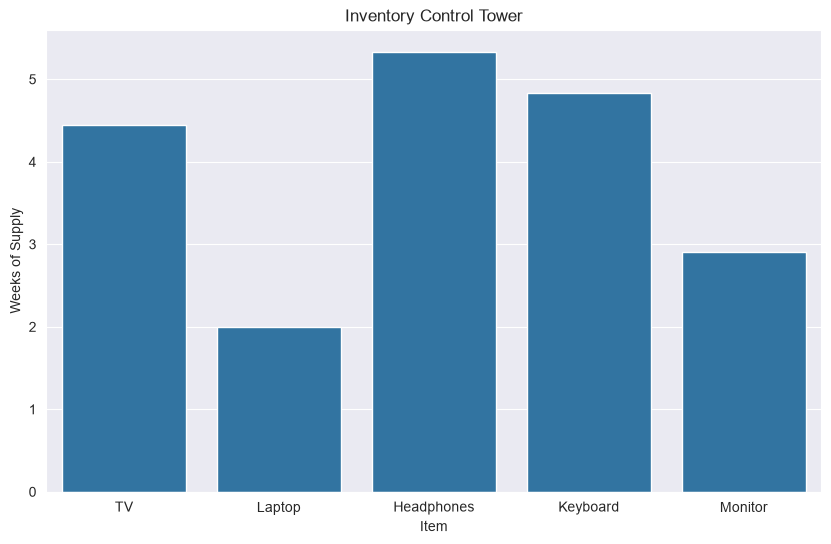

In [11]:
## Inventory Status Chart

plt.figure(figsize=(10,6))

sns.barplot(

    data=control_tower_df,

    x="Item",

    y="Weeks_of_Supply"

)

plt.title("Inventory Control Tower")

plt.ylabel("Weeks of Supply")

plt.show()

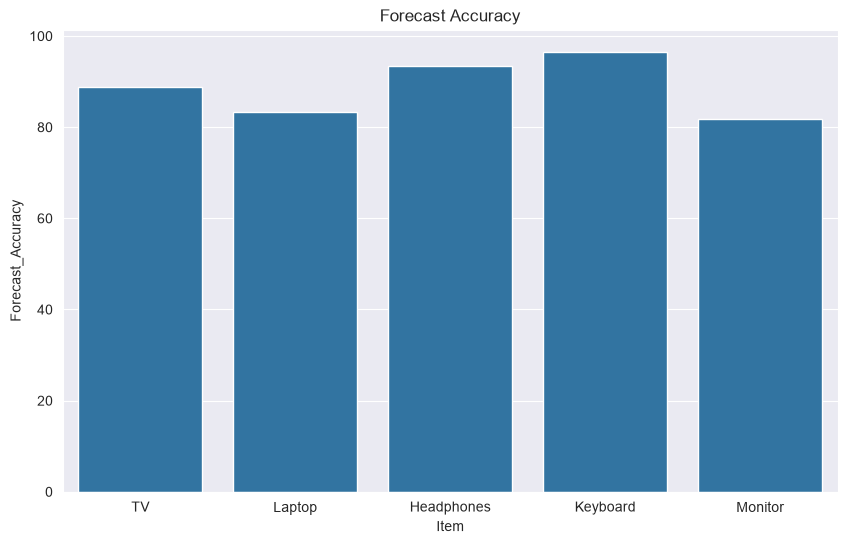

In [12]:
## Forecast Accuracy Chart

plt.figure(figsize=(10,6))

sns.barplot(

    data=control_tower_df,

    x="Item",

    y="Forecast_Accuracy"

)

plt.title("Forecast Accuracy")

plt.show()

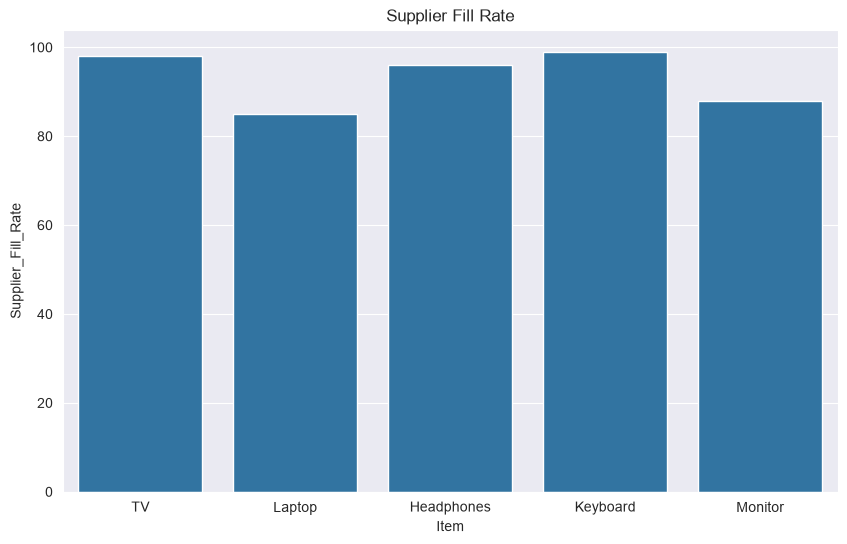

In [13]:
## Supplier Fill Rate

plt.figure(figsize=(10,6))

sns.barplot(

    data=control_tower_df,

    x="Item",

    y="Supplier_Fill_Rate"

)

plt.title("Supplier Fill Rate")

plt.show()

In [14]:
## Critical Item Alert Engine

alerts = control_tower_df[

    control_tower_df["Priority"] == "Critical"

]

alerts

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply,Inventory_Status,Supplier_Risk,Risk_Score,Priority


In [15]:
## Executive Metrics

print("CONTROL TOWER KPI SUMMARY")

print()

print(
    f"Total Inventory: "
    f"{control_tower_df['Inventory'].sum():,.0f}"
)

print(
    f"Average Forecast Accuracy: "
    f"{control_tower_df['Forecast_Accuracy'].mean():.1f}%"
)

print(
    f"Average Fill Rate: "
    f"{control_tower_df['Supplier_Fill_Rate'].mean():.1f}%"
)

CONTROL TOWER KPI SUMMARY

Total Inventory: 2,200
Average Forecast Accuracy: 88.8%
Average Fill Rate: 93.2%


In [16]:
## Auto Recommendations

def recommendation(priority):

    if priority == "Critical":
        return "Immediate Action"

    elif priority == "Monitor":
        return "Weekly Review"

    else:
        return "No Action Needed"


control_tower_df["Recommendation"] = (
    control_tower_df["Priority"]
    .apply(recommendation)
)

display(control_tower_df)

,Item,Inventory,Forecast,Actual_Demand,Supplier_Fill_Rate,Forecast_Error,Forecast_Accuracy,Weeks_of_Supply,Inventory_Status,Supplier_Risk,Risk_Score,Priority,Recommendation
0,TV,500,400,450,98,-50,88.888889,4.444444,Balanced,Normal,0,Normal,No Action Needed
1,Laptop,150,250,300,85,-50,83.333333,2.000000,Balanced,High Risk,1,Monitor,Weekly Review
2,Headphones,1000,800,750,96,50,93.333333,5.333333,Balanced,Normal,0,Normal,No Action Needed
3,Keyboard,350,300,290,99,10,96.551724,4.827586,Balanced,Normal,0,Normal,No Action Needed
4,Monitor,200,225,275,88,-50,81.818182,2.909091,Balanced,High Risk,1,Monitor,Weekly Review


In [17]:
## Executive Summary Generator

summary = f"""

Inventory Control Tower Summary

Average Forecast Accuracy:
{control_tower_df['Forecast_Accuracy'].mean():.1f}%

Average Supplier Fill Rate:
{control_tower_df['Supplier_Fill_Rate'].mean():.1f}%

Critical Items:
{len(control_tower_df[control_tower_df['Priority']=='Critical'])}

"""

print(summary)



Inventory Control Tower Summary

Average Forecast Accuracy:
88.8%

Average Supplier Fill Rate:
93.2%

Critical Items:
0




In [18]:
## Talking Points

print("""

CONTROL TOWER BUSINESS VALUE

1. Improves inventory visibility

2. Detects stockout risks early

3. Prioritizes inventory actions

4. Improves forecast monitoring

5. Enhances supplier management

6. Supports executive decision making

7. Balances inventory and customer service

""")



CONTROL TOWER BUSINESS VALUE

1. Improves inventory visibility

2. Detects stockout risks early

3. Prioritizes inventory actions

4. Improves forecast monitoring

5. Enhances supplier management

6. Supports executive decision making

7. Balances inventory and customer service




In [19]:
## Portfolio Capstone Statement

print("""

CAPSTONE PROJECT

Developed an Inventory Control Tower
to monitor inventory health, forecast
accuracy, supplier performance,
and enterprise inventory risks.

Provides real-time decision support
for inventory flow leadership teams.

""")



CAPSTONE PROJECT

Developed an Inventory Control Tower
to monitor inventory health, forecast
accuracy, supplier performance,
and enterprise inventory risks.

Provides real-time decision support
for inventory flow leadership teams.


